# Sistema di Face Detection per una fotocamera digitale

Svilupperemo una pipeline che identifichi i volti presenti nelle immagini e restituisca le coordinate dei bounding box dove i volti sono individuati. Se non ci sono volti, la pipeline restituirà una lista vuota.

_La pipeline deve essere in grado di:_
- prendere un’immagine in ingresso.
- restituire una lista di coordinate dei bounding box dove sono presenti volti.
- restituire una lista vuota se nell’immagine non ci sono volti.

_Limitazioni:_
- non abbiamo un dataset di partenze, per cui cercheremo un dataset adatto in rete.
- il modello di Face Detection verrà addestrato da zero con Scikit-learn.
- il modello dovrà essere ottimizzato per utilizzare poche risorse.

# Bibliografia
Abbiamo studiato diverso materiale per impostare il codice e selezionato i seguenti come materiale principale. Si tratta di alcuni paper scientifici sullo stato dell'arte dei moderni meccanismi di face detection, ma anche sugli importanti step teorici che hanno portato ai codici di oggi. In più abbiamo inserito le pagine specifiche delle funzioni di sklearn che verranno utilizzate per epplicare il nostro modello.

- [1] Andisani Nemavhola, Serestina Viriri, Colin Chibaya, 'A Scoping Review of Literature on Deep Learning Techniques for Face Recognition', Wiley, Human Behavior and Emerging Technologies, Volume 2025, Article ID 5979728, 14 pages:
https://drive.google.com/file/d/1jzaJkiOzdgwn-nC8XTrLQbNyqFC7x2R-/view?usp=sharing

- [2] Shervin Minaee, Ping Luo, Zhe Lin, Kevin Bowyer, 'Going Deeper Into Face Detection: A Survey', arXiv:2103.14983v2  [cs.CV]  13 Apr 2021:
https://drive.google.com/file/d/1MLAWU3A0Nam5C3fsKmLjtPAJSBmOYFWz/view?usp=sharing

- [3] Paul Viola, Michael J. Jones, 'Robust Real-Time Face Detection', International Journal of Computer Vision 57(2), 137–154, 2004:
https://drive.google.com/file/d/1Uv6xz7YHmjBlO-_xkNlJXwnU35oyBebt/view?usp=sharing

- [4] Stefan van der Walt, Johannes L. Schonberger, Juan Nunez-Iglesias, Francois Boulogne, Joshua D. Warner, Neil Yager, Emmanuelle Gouillart, Tony Yu and the scikit-image contributors, 'Scikit-image: image processing in Python' Van der Walt et al. (2014), PeerJ, DOI 10.7717/peerj.453:
https://drive.google.com/file/d/148FeVtGAAU2GAGFiwmRBFraZhTMTv5w5/view?usp=sharing

- [5] HOG features: https://scikit-image.org/docs/stable/auto_examples/features_detection/plot_hog.html

- [6] Pyramid Search: https://pyimagesearch.com/2015/03/16/image-pyramids-with-python-and-opencv/

- [7] Sliding Windows: https://pyimagesearch.com/2015/03/23/sliding-windows-for-object-detection-with-python-and-opencv/

- [8] Non Max Suppression: https://pyimagesearch.com/2015/02/16/faster-non-maximum-suppression-python/

- [9] N. Dalal and B. Triggs, 'Histograms of oriented gradients for human detection,' 2005 IEEE Computer Society Conference on Computer Vision and Pattern Recognition (CVPR'05), San Diego, CA, USA, 2005, pp. 886-893 vol. 1, doi: 10.1109/CVPR.2005.177. keywords: {Histograms;Humans;Robustness;Object recognition;Support vector machines;Object detection;Testing;Image edge detection;High performance computing;Image databases},




Dalla letteratura consultata possiamo ricavare spunti per la realizzazione del modello:
- la maggior parte dei modelli è addestrata su dataset con foto di volti puliti [1]; se questo può essere un limite per alcuni modelli  e progetti (visto che nei casi applicativi si hanno raramente visi in posizione e illuminazione ottimali), non lo è per noi che vogliamo elaborare un modello per una fotocamera per selfies, che quindi ha tendenzialmente a che fare con volti a distanza abbastanza regolare e posti in posizione favorevole alla camera.

- i modelli che danno migliori risultati sono [1][2]:
  * modelli basati su CNN
  * R-CNN e Fast-RCNN
  * Single Shot Detector
  * Feature Pyramid Network

Visto che noi vogliamo addestrare un modello partendo da zero con SciKit-Learn non possiamo utilizzare o produre dei modelli CNN. Abbiamo perciò consultato articoli di face detection precedenti [3] in modo da vedere come utilizzare i modelli di ML per ottenere comunque delle buone metriche.

 Possiamo pensare di lavorare per produrre un modello a più strati[5][6][7][8] con:
- estrazione delle feature con HOG (Histogram of Oriented Gradients)
- allenare un classificatore con Sklearn
- produrre una Sliding Window + Image Pyramid per rilevare volti in immagini di dimensioni arbitrarie

Per il dataset dagli articoli vengono segnalati [1] CelebFaces Attributes (Celeba su Kaggle), Face Detection Data Set and Benchmark (FDDB).
Abbiamo valutato di utilizzare più dataset da combinare per ottenere un dataset adeguato su cui addestrare il modello.

In [ ]:
# Per pulire File prima di eseguire da capo NB
!rm -rf /content/*

In [ ]:
import numpy as np
import os
import zipfile
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import random
from skimage.feature import hog
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
import joblib
import imutils
from google.colab.patches import cv2_imshow
from PIL import Image
import seaborn as sns

## Funzioni necessrie per il processing dei dati

Definiamo due funzioni che ci permettano rapidamente di valutare la composizione dei dataset:
- *size*: restituisce la dimensione minima delle immagini contenute nel dataset e ci serve per valutare la scala da impostare per la face detection
- *square*: ci dice quante immagini quadrate e non sono contenute nel dataset. Importante per addestrare il modello su immagini della stessa forma.

In [ ]:
def size(folder_path):
  sizes = set()

  for root, dirs, files in os.walk(folder_path):
      for f in files:
          if f.lower().endswith(('.jpg','.jpeg','.png')):
              path = os.path.join(root, f)
              try:
                  img = Image.open(path)
                  sizes.add(img.size)
              except:
                  pass

  print('Dimensione minima:', min(sizes))

In [ ]:
def square(folder_path):
    square = 0
    non_square = 0
    total_files = 0

    if not os.path.exists(folder_path):
        print(f'Errore: Il percorso {folder_path} non esiste.')
        return

    for root, dirs, files in os.walk(folder_path):
        for f in files:
            if f.lower().endswith(('.jpg', '.jpeg', '.png')):
                total_files += 1
                path = os.path.join(root, f)
                try:
                    with Image.open(path) as img:
                        w, h = img.size
                        if w == h:
                            square += 1
                        else:
                            non_square += 1
                except Exception as e:
                    print(f'Impossibile leggere {f}: {e}')

    print(f'Report per: {os.path.basename(folder_path)}:')
    print('Totale immagini analizzate:', square + non_square)
    print('Quadrate:', square)
    print('Non quadrate:', non_square)

Carico le credenziali Kaggle per caricare i dataset necessari.

In [ ]:
from google.colab import userdata
!pip install -q kaggle

os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')

## CREAZIONE DATASET
La creazione del dataset apre alcune opzioni da valutare; a noi serve un dataset bilanciato di facce e non facce con varietà di figure per entrambi i casi e una buona qualità per poter ottenere anche i dettagli.
Inoltre il nostro modello verrà allentato con dei box quadrati, che ci porta ad utilizzare dei dataset quadrati.
I dataset trovati hanno molte forme e dimensioni differenti. Possiamo scegliere se ritagliare con varie tecniche (Center Cropping, Face-Aligned Cropping) delle immagini quadrate dai dataset di partenza oppure se modificare le immagini inserendo delle deformazioni che possono avere effetti negativi sull'addestramento.

## __FACES__

**FaceScrub**

In [ ]:
!kaggle datasets download -d rajnishe/facescrub-full

DATA_FOLDER = '/content/data'
os.makedirs(DATA_FOLDER, exist_ok=True)

ZIP_FILE = '/content/facescrub-full.zip'

with zipfile.ZipFile(ZIP_FILE, 'r') as zip_ref:
    zip_ref.extractall(DATA_FOLDER)

Dataset URL: https://www.kaggle.com/datasets/rajnishe/facescrub-full
License(s): GNU Affero General Public License 3.0
100% 645M/645M [00:07<00:00, 96.3MB/s]



In [ ]:
size(DATA_FOLDER)
square(DATA_FOLDER)

Dimensione minima: (103, 103)
Report per: data:
Totale immagini analizzate: 43124
Quadrate: 43124
Non quadrate: 0


**CelebA**

In [ ]:
!kaggle datasets download -d jessicali9530/celeba-dataset

DATA_FOLDER = '/content/data'
os.makedirs(DATA_FOLDER, exist_ok=True)

ZIP_FILE = '/content/celeba-dataset.zip'

with zipfile.ZipFile(ZIP_FILE, 'r') as zip_ref:
    zip_ref.extractall(DATA_FOLDER)

print('Dataset estratto in:', DATA_FOLDER)

Dataset URL: https://www.kaggle.com/datasets/jessicali9530/celeba-dataset
License(s): other
100% 1.33G/1.33G [00:12<00:00, 115MB/s]

Dataset estratto in: /content/data


In [ ]:
CELEBA='/content/data/img_align_celeba'
size(CELEBA)
square(CELEBA)

Dimensione minima: (178, 218)
Report per: img_align_celeba:
Totale immagini analizzate: 202599
Quadrate: 0
Non quadrate: 202599


## __NON FACES__

**Unlabeled Images**

In [ ]:
!kaggle datasets download -d jessicali9530/stl10

ZIP_FILE = '/content/stl10.zip'

with zipfile.ZipFile(ZIP_FILE, 'r') as zip_ref:
    for member in zip_ref.namelist():
        if member.startswith('unlabeled_images/') and not member.endswith('/'):
            zip_ref.extract(member, DATA_FOLDER)

Dataset URL: https://www.kaggle.com/datasets/jessicali9530/stl10
License(s): other
100% 1.88G/1.88G [00:18<00:00, 108MB/s]



In [ ]:
UNLABELED_IMG='/content/data/unlabeled_images'
size(UNLABELED_IMG)
square(UNLABELED_IMG)

Dimensione minima: (96, 96)
Report per: unlabeled_images:
Totale immagini analizzate: 100000
Quadrate: 100000
Non quadrate: 0


**CIFAR 10**

In [ ]:
!kaggle datasets download -d swaroopkml/cifar10-pngs-in-folders

DATA_FOLDER = '/content/data'
os.makedirs(DATA_FOLDER, exist_ok=True)

ZIP_FILE = '/content/cifar10-pngs-in-folders.zip'

with zipfile.ZipFile(ZIP_FILE, 'r') as zip_ref:
    zip_ref.extractall(DATA_FOLDER)

print('Dataset estratto in:', DATA_FOLDER)

Dataset URL: https://www.kaggle.com/datasets/swaroopkml/cifar10-pngs-in-folders
License(s): unknown
100% 140M/140M [00:01<00:00, 117MB/s]

Dataset estratto in: /content/data


In [ ]:
CIFAR10='/content/data/cifar10'
size(CIFAR10)
square(CIFAR10)

Dimensione minima: (32, 32)
Report per: cifar10:
Totale immagini analizzate: 60000
Quadrate: 60000
Non quadrate: 0


I dataset scaricati hanno caratteristiche differenti per dimensione e forma delle singole immagini.
Per addestrare il modello vogliamo utilizzare immagini quadrate con una buona qualità in modo da poter valutare meglio le caratteristiche.
I due datasete CelebA e Cifar10 contengono unicamente immagini non quadrate. Inoltre Cifar10 ha immagini di dimensione estremamente piccola (32x32): scegliamo quindi di utilizzare gli altri due dataset per addestrare il modello utilizzando immagini già quadrate e non dovendo fare reshaping sul dataset, che rischia di deformare le immagini e influire negativamente sul modello.

- nota su dimensione di Cifar10: il dataset contiene immagini di non volti con dimensione molto bassa. Per quanto per il nostro modello sia importante imparare a riconoscere le caratteristiche di un volto, allenarlo su un dataset di non volti con immagini poco definite può portarci ad avere difficoltà anche nel riconoscimento dei volti. E' quindi importante che anche il dataset di non volti contenga immagini varie e non sfondi neutri o immagini poco definite.

- nota sul dataset Faces: la scelta di utilizzare per i volti un dataset contenente immagini di personaggi famosi ci da una buona varietà di volti relativi però a fisionomie prevalentemente occidentali. Questo potrebbe introdurre degli errori nel modello su altri volti.

Creiamo una funzione *data_selection* che estrae casualmente dalla cartella scelta immagini quadrate e le metta nel dataset per l'addestramento ridotte alla dimensione selezionata (PATCH_SIZE=96) e in scala di grigi.

In [ ]:
def data_selection(input_path, output_folder, patch_size, num):
    os.makedirs(output_folder, exist_ok=True)

    all_images = []

    if not os.path.exists(input_path):
        print(f'Errore: Il percorso {input_path} non esiste.')
        return

    for root, _, files in os.walk(input_path):
        for f in files:
            if f.lower().endswith(('.png', '.jpg', '.jpeg')):
                all_images.append(os.path.join(root, f))

    random.shuffle(all_images)
    print(f'\nCartella: {os.path.basename(input_path)}')
    print(f'Immagini totali trovate nella sorgente: {len(all_images)}')

    saved_count = 0
    skipped_aspect_ratio = 0
    total_scanned = 0

    for img_path in all_images:
        if saved_count >= num:
            break

        total_scanned += 1
        try:
            with Image.open(img_path) as img:
                width, height = img.size

                # Controllo quadratura
                if width != height:
                    skipped_aspect_ratio += 1
                    continue

                img = img.convert('L')
                img = img.resize((patch_size, patch_size), Image.Resampling.LANCZOS)

                folder_name = os.path.basename(input_path)
                save_path = os.path.join(output_folder, f'{folder_name}_{saved_count}.jpg')

                img.save(save_path, quality=95)
                saved_count += 1

        except Exception as e:
            print(f'Errore con {img_path}: {e}')

    print(f'Scansione completata. Analizzate {total_scanned} immagini per trovarne {saved_count} quadrate.')
    print(f'Scartate (non quadrate) durante il processo: {skipped_aspect_ratio}')

    if saved_count < num:
        print(f'NOTA: Sono state trovate solo {saved_count} immagini quadrate su {num} richieste.')

Le cartelle su cui lavoriamo e la dimensione scelta (data dal valore minimo delle dimensioni dei dataset in ingresso) sono:

In [ ]:
faces_output = '/content/dataset/faces'
non_faces_output = '/content/dataset/non_faces'

PATCH_SIZE = 96

actor='/content/data/actor_faces'
actress='/content/data/actress_faces'
CELEBA='/content/data/img_align_celeba'
UNLABELED_IMG='/content/data/unlabeled_images'

In [ ]:
data_selection(actor, faces_output, PATCH_SIZE, 3000)


Cartella: actor_faces
Immagini totali trovate nella sorgente: 23205
Scansione completata. Analizzate 3000 immagini per trovarne 3000 quadrate.
Scartate (non quadrate) durante il processo: 0


In [ ]:
data_selection(actress, faces_output, PATCH_SIZE, 3000)


Cartella: actress_faces
Immagini totali trovate nella sorgente: 19919
Scansione completata. Analizzate 3000 immagini per trovarne 3000 quadrate.
Scartate (non quadrate) durante il processo: 0


Verifico contenuto della cartella *Faces*:

In [ ]:
size(faces_output)
square(faces_output)

Dimensione minima: (96, 96)
Report per: faces:
Totale immagini analizzate: 6000
Quadrate: 6000
Non quadrate: 0


In [ ]:
data_selection(UNLABELED_IMG, non_faces_output, PATCH_SIZE, 6000)


Cartella: unlabeled_images
Immagini totali trovate nella sorgente: 100000
Scansione completata. Analizzate 6000 immagini per trovarne 6000 quadrate.
Scartate (non quadrate) durante il processo: 0


Verifico contenuto della cartella *Non Faces*:

In [ ]:
size(non_faces_output)
square(non_faces_output)

Dimensione minima: (96, 96)
Report per: non_faces:
Totale immagini analizzate: 6000
Quadrate: 6000
Non quadrate: 0


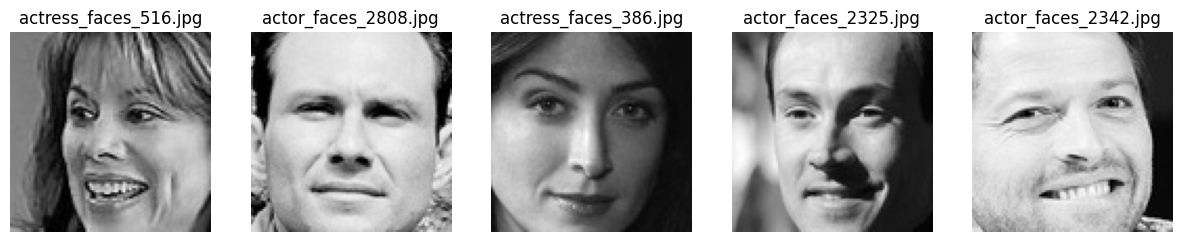

In [ ]:
FACES_DIR = '/content/dataset/faces'
faces = os.listdir(FACES_DIR)

sample_images = random.sample(faces, 5)

plt.figure(figsize=(15,5))

for i, img_name in enumerate(sample_images):
    img_path = os.path.join(FACES_DIR, img_name)

    img = Image.open(img_path)

    plt.subplot(1,5,i+1)
    plt.imshow(img, cmap='gray')
    plt.title(img_name)
    plt.axis('off')

plt.show()

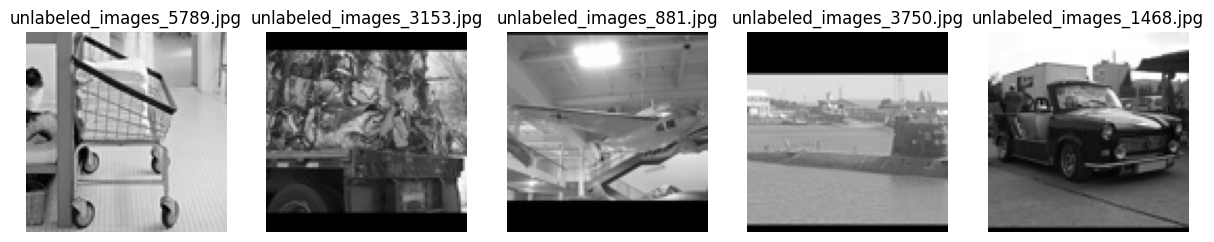

In [ ]:
THINGS_DIR = '/content/dataset/non_faces'

things = os.listdir(THINGS_DIR)

sample_images = random.sample(things, 5)

plt.figure(figsize=(15,5))

for i, img_name in enumerate(sample_images):
    img_path = os.path.join(THINGS_DIR, img_name)

    img = Image.open(img_path)

    plt.subplot(1,5,i+1)
    plt.imshow(img, cmap='gray')
    plt.title(img_name)
    plt.axis('off')

plt.show()

Abbiamo composto il dataset con 6000 immagini di faces (metà uomini e metà donne) e altrettante immagini di non faces. Nonostante nei casi su cui poi verrà applicato il modello le faces saranno molto meno numerose dei casi non faces si è scelto di addestrare il modello su un dataset bilanciato per non introdurre dei parametri nascosti che potrebbero inficiare il risultato successivo. La rigidità o permissività del riconosocimento dei volti nella parte di applicazione verrà regolata ulteriormente con la scelta dei parametri nella seconda parte.

## Creazione Train e Test e assgnazione delle classi

L'estrazione della HOG Features viene fatta utilizzando la funzione hog, del pacchetto scikitlearn [5].

**PARAMETRI HOG**

- Inserisco *channel_axis=None* di modo che la funzione hog non cerchi più canali (leagati a immagini a colore) in un dataset che ho già convertito in scala di grigi.
-  *orientations=12*: Più orientamenti aumentano la capacità del descrittore di catturare dettagli, ma aumentano anche la dimensione del vettore delle caratteristiche.
- *pixels_per_cell=(6, 6)*: dimensioni in pixel di ogni cella. Celle più piccole catturano più dettagli locali, mentre celle più grandi riducono la dimensione del vettore delle caratteristiche ma possono perdere dettagli fini.
- *cells_per_block=(2, 2)*: I blocchi aiutano a normalizzare le caratteristiche su diverse regioni dell'immagine, migliorando la robustezza alle variazioni di illuminazione.
- *normalizzazione L2-Hys*: necessaria per rendere l'estrazione dei gradienti più resistente ai cambi di luminostià tra le immagini.

La funzione mappa le immagini utilizzando i parametri e resituisce un array nunpy delle features che rappresenta i gradienti contenuti.


### PARAMETRI
Impostiamo nella seguente cella tutti i parametri che saranno necessari nell'addestramento del modello e nella sua applicazione successiva. Questo è importante per aumentare il controllo e non avere pezzi del codice che lavorano con parametri differenti.

In [ ]:
# Parametri HOG
ORIENTATIONS=12
PIXELS_PER_CELL=6
CELLS_PER_BLOCK=2

# Ridimensionamento Immagini finali
TARGET_SIZE=600

# Parametri Scaling e Sliding
PYRAMID_SCALE=1.2
STEP_SIZE=8
SVM_THRESHOLD=0.12 # soglia faces/non faces
NMS_THRESHOLD=0.35 # soglia non maximum suppression (% di sovrapposizione)

In [ ]:
def extract_hog_features(image_paths):
    features = []
    for path in image_paths:
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        if img is None: continue

        feat = hog(
            img,
            orientations=ORIENTATIONS,
            pixels_per_cell=(PIXELS_PER_CELL, PIXELS_PER_CELL),
            cells_per_block=(CELLS_PER_BLOCK, CELLS_PER_BLOCK),
            block_norm='L2-Hys',
            visualize=False,
            channel_axis=None
        )
        features.append(feat)
    return np.array(features)

In [ ]:
def plot_confusion_matrix(y_true, y_pred, labels=['Negative', 'Positive'], show_precision_recall = False):
    cm = confusion_matrix(y_true, y_pred)
    df_cm = pd.DataFrame(cm, index=labels, columns=['Predicted '+labels[0], 'Predicted '+ labels[1]])

    sns.heatmap(df_cm, annot=True, fmt='g')

    if show_precision_recall:
      plt.text(0, -0.1, f'Precision: {cm[1][1]/(cm[1][1]+cm[0][1]):.3f}')
      plt.text(1, -0.1, f'Precision: {cm[1][1]/(cm[1][1]+cm[1][0]):.3f}')
    plt.show()

## Assegnazione delle classi
- **classe 1**-faces
- **classe 0**-non faces

Nell'assegnazione delle classi viene creata una variabile *y* con valore 0 o 1 assegnata ad ogni foto (inserite nella variabile X).

In [ ]:
faces_files = os.listdir(FACES_DIR)
things_files = os.listdir(THINGS_DIR)

faces = [os.path.join(FACES_DIR, f) for f in faces_files]
faces_labels = [1] * len(faces)

non_faces = [os.path.join(THINGS_DIR, f) for f in things_files]
non_faces_labels = [0] * len(non_faces)

In [ ]:
X = faces + non_faces

y = faces_labels + non_faces_labels

print('Totale immagini:', len(X))
print('Totale etichette 1:', sum(y), 'Totale etichette 0:', len(y) - sum(y))

Totale immagini: 12000
Totale etichette 1: 6000 Totale etichette 0: 6000


Scegliamo di mettere il test_size al 30% anche per poter valutare meglio cosa sta sbagliando il modello (falsi positivi o falsi negativi) e poter intervenire con il settaggio dei parametri nella parte successiva.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

In [ ]:
print('Estrazione HOG features per train set')
X_train_hog = extract_hog_features(X_train)
print('Estrazione HOG features per test set')
X_test_hog = extract_hog_features(X_test)

print('Train HOG shape:', X_train_hog.shape, 'Test HOG shape:', X_test_hog.shape)

Estrazione HOG features per train set
Estrazione HOG features per test set
Train HOG shape: (8400, 10800) Test HOG shape: (3600, 10800)


In [ ]:
scaler = StandardScaler()
X_train_hog = scaler.fit_transform(X_train_hog)
X_test_hog = scaler.transform(X_test_hog)

Nella preparazione del codice per addestrare il modello abbiamo utilizzato dei subset più piccoli per verificare il comportamento del modello in maniera più veloce. Manteniamo questo meccanismo in modo da poter variare in maniera rapida e robusta la percentuale di set da utilizzare ogni volta.

In [ ]:
subset_percentage = 1

N_subset = int(len(X_train_hog) * subset_percentage)

print(f'Utilizzo il {subset_percentage*100}% del dataset: {N_subset} campioni su {len(X_train_hog)}')

Utilizzo il 100% del dataset: 8400 campioni su 8400


Avevamo in precedenza utilizzato un kernell lineare che non ci dava buoni risultati. Abbiamo trovato maggior efficacia con kernel gaussiano *rbf* e abbiamo scelto pertanTo di addestrare il modello con una RandomizedSearch su una param distribution in modo da non appesantirne la velocità.

In [ ]:
param_distributions = {
    'C': [0.1, 1, 10],
    'gamma': [0.0001, 0.001, 'scale']
}

random_search = RandomizedSearchCV(
    SVC(kernel='rbf', probability=False),
    param_distributions=param_distributions,
    n_iter=3,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42
)

random_search.fit(X_train_hog[:N_subset], y_train[:N_subset])

clf = random_search.best_estimator_

print(f'Migliori parametri trovati: {random_search.best_params_}')

Migliori parametri trovati: {'gamma': 'scale', 'C': 1}


In [ ]:
y_pred = clf.predict(X_test_hog)
y_train_pred = clf.predict(X_train_hog)

print(f'Accuracy Train: {accuracy_score(y_train, y_train_pred):.4f}')
print(f'Accuracy Test:  {accuracy_score(y_test, y_pred):.4f}')
print('\nReport finale:\n', classification_report(y_test, y_pred, target_names=['Non-Face', 'Face'], digits=3))

Accuracy Train: 0.9999
Accuracy Test:  0.9986

Report finale:
               precision    recall  f1-score   support

    Non-Face      0.997     1.000     0.999      1800
        Face      1.000     0.997     0.999      1800

    accuracy                          0.999      3600
   macro avg      0.999     0.999     0.999      3600
weighted avg      0.999     0.999     0.999      3600



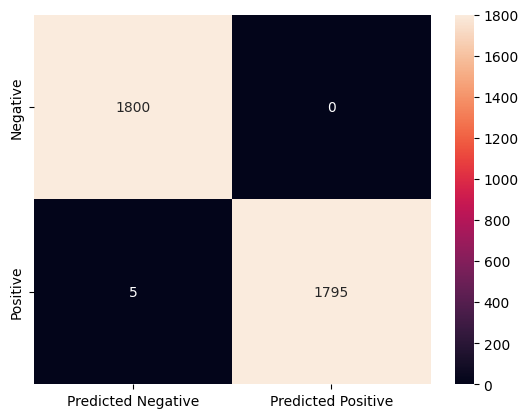

In [ ]:
plot_confusion_matrix(y_test, y_pred)

In [ ]:
joblib.dump(clf, 'model_facedet.joblib')

['model_facedet.joblib']

Il modello costruito ha delle ottime metriche che fanno intendere una presenza di overfitting nel Train. Le metriche sul Test restano però ottime per cui possiamo valutare l'efficacia applicandolo su un nuovo dataset con immagini varie. Possiamo vedere una leggera preponderanza di falsi negativi che potremo valutare nell'impostazione dei parametri per la face detection.

# APPLICAZIONE DEL MODELLO

Utilizziamo il seguente dataset che contiene immagini con più volti in vari ambienti.

In [ ]:
!kaggle datasets download -d sbaghbidi/human-faces-object-detection
!unzip human-faces-object-detection.zip

Dataset URL: https://www.kaggle.com/datasets/sbaghbidi/human-faces-object-detection
License(s): unknown
100% 498M/498M [00:07<00:00, 72.9MB/s]

Archive:  human-faces-object-detection.zip
  inflating: faces.csv               
  inflating: images/00000003.jpg     
  inflating: images/00000004.jpg     
  inflating: images/00000005.jpg     
  inflating: images/00000006.jpg     
  inflating: images/00000008.jpg     
  inflating: images/00000011.jpg     
  inflating: images/00000012.jpg     
  inflating: images/00000015.jpg     
  inflating: images/00000018.jpg     
  inflating: images/00000020.jpg     
  inflating: images/00000022.jpg     
  inflating: images/00000023.jpg     
  inflating: images/00000024.jpg     
  inflating: images/00000026.jpg     
  inflating: images/00000031.jpg     
  inflating: images/00000032.jpg     
  inflating: images/00000041.jpg     
  inflating: images/00000044.jpg     
  inflating: images/00000045.jpg     
  inflating: images/00000047.jpg     
  inflating: im

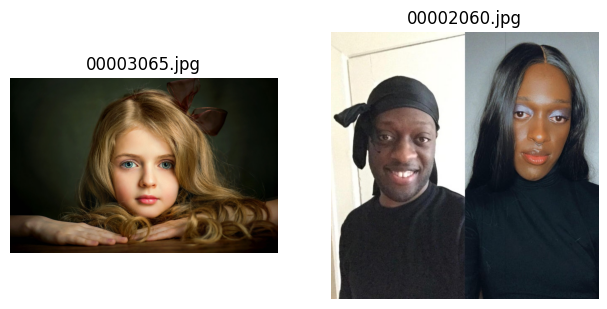

In [ ]:
image_dir = '/content/images'

images = os.listdir(image_dir)

sample_images = random.sample(images, 2)

plt.figure(figsize=(20,14))

for i, img_name in enumerate(sample_images):
    img = cv2.imread(os.path.join(image_dir, img_name))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(1,5,i+1)
    plt.imshow(img)
    plt.axis('off')
    plt.title(img_name)

plt.show()

In [ ]:
size(image_dir)
square(image_dir)

Dimensione minima: (150, 150)
Report per: images:
Totale immagini analizzate: 2204
Quadrate: 90
Non quadrate: 2114


Per applicare il modello e sviluppare il meccanismo di face detection ci siamo rifatti alla letteratura [6][7], utilizzando le funzioni PyramidSearch e Sliding Windows.
Il meccanismo ridimensiona la foto in analisi facendo scorrere una finestra di dimensione fissata al suo interno per verificare la presenza di volti con il modello.

### __Non Max Suppression__

La funzione *non_max_suppression* scorre i vari bounding box trovati e verifica se si sovrappongono più di un parametro scelto (*overlapThresh*) e selezionando il box con probabilità maggiore (*pick*).

In [ ]:
def non_max_suppression(boxes, probs, overlapThresh):
    if len(boxes) == 0: return [], []

    pick = []
    x1, y1, x2, y2 = boxes[:,0], boxes[:,1], boxes[:,2], boxes[:,3]
    area = (x2 - x1 + 1) * (y2 - y1 + 1)
    idxs = np.argsort(probs)[::-1]

    while len(idxs) > 0:
        i = idxs[0]
        pick.append(i)

        xx1 = np.maximum(x1[i], x1[idxs[1:]])
        yy1 = np.maximum(y1[i], y1[idxs[1:]])
        xx2 = np.minimum(x2[i], x2[idxs[1:]])
        yy2 = np.minimum(y2[i], y2[idxs[1:]])

        w = np.maximum(0, xx2 - xx1 + 1)
        h = np.maximum(0, yy2 - yy1 + 1)

        overlap = (w * h) / area[idxs[1:]]
        idxs = np.delete(idxs, np.concatenate(([0], np.where(overlap > overlapThresh)[0] + 1)))

    return boxes[pick], probs[pick]

In [ ]:
n_blocks_axis = (PATCH_SIZE // PIXELS_PER_CELL) - CELLS_PER_BLOCK + 1
EXPECTED_FEATURES = (n_blocks_axis**2) * (CELLS_PER_BLOCK**2) * ORIENTATIONS

print(f"Ogni finestra deve produrre esattamente {EXPECTED_FEATURES} features.")

Ogni finestra deve produrre esattamente 10800 features.


### __Image Pyramid__

La funzione image_pyramid serve a ridimensionare l'immagine di partenza in modo da poter cercare volti di varie dimensioni contenuti nell'immagine. I parametri necessari sono:
- *scale_factor*: rappresenta la proporzione di ridimensionamento dell'immagine
- *min_size*: indica la dimensione minima a cui viene effettuata la ricerca. Se non fosse fissata una dimensione minima il ciclo proseguirebbe fino a ridurre l'immagine ad un unico pixell.
- la funzione *yield* al posto di *return* serve a non generare effettivamente tutte le immagini scalate che generiamo in modo da non saturare la RAM.

In [ ]:
def image_pyramid(image, scale_factor, min_size):
    yield image, 1.0

    current_scale = 1.0
    current_image = image.copy()

    while True:
        current_scale *= scale_factor

        new_w = int(image.shape[1] / current_scale)
        new_h = int(image.shape[0] / current_scale)

        if new_w < min_size[0] or new_h < min_size[1]:
            break

        resized = cv2.resize(image, (new_w, new_h), interpolation=cv2.INTER_AREA)

        yield resized, current_scale

### __Find Face__

La funzione *find_faces* combina le due precedenti nella ricerca dei volti. Sono stati inseriti qui i parametri fondamentali per regolare la severità della ricerca del modello:
- *piramid scale*: definisce come già detto il ritmo di ridimensionamento
- *step size*: dimensiona lo spostamento della ricerca nella sliding windows
- *svm threshold*: indica la severità con cui il nostro classificatore SVM accetta o rifiuta i volti. Nonostante il numero di falsi negativi che il modello mostrava sul test set abbiamo impostato questo threshold a 0.12 per evitare di avere troppi falsi negativi.
- *nms threshold*: indica la soglia accettata di sovrapposizione della non maximum sopppressione (nms).

Il parametro *target size* è stato inzerito per ridimensionare le immagini su cui viene applicato il modello prima di applicarlo. Questo si è reso necessario perchè il dataset contiene immagini di dimensioni molto diverse che portavano ad avere tempi di applicazione e costi computazionali differenti. In questa maniera possiamo più facilmente valutare la applicazione del modello.

Nella funzione ci sono due ulteriori accorgimenti da valutare:
-         hog_full = hog(layer,
                       orientations=ORIENTATIONS,
                       pixels_per_cell=(p_cell, p_cell),
                       cells_per_block=(c_blk, c_blk),
                       block_norm='L2-Hys',
                       feature_vector=False)
   Si è scelto di applicare la funzione HOG a tutta la immagine di test utilizzando gli stessi parametri dell'addestramento e poi fare la scansione sulla mappa complessiva invece che applicare la funzione hog ad ogni diversa scansione. Questo ci permette di avere un ciclo più rapido e efficiente.

- Avendo fatto una serie di ridimensionamenti dell'immagine (all'inizio per standardizzare la dimensione e poi col pyramid scaling) abbiamo dovuto prestare molta attenzione al ridimensionamento inverso delle coordinate dei bounding box perchè siano effettivmente posizionati correttamente rispetto ai volti.

In [ ]:
def find_faces(image, clf, scaler,
               target_size=TARGET_SIZE,
               pyramid_scale=PYRAMID_SCALE,
               step_size=STEP_SIZE,
               svm_threshold=SVM_THRESHOLD,
               nms_threshold=NMS_THRESHOLD):

    # 1. Pre-processing e Resize Iniziale
    h_orig, w_orig = image.shape[:2]
    initial_scale = target_size / max(h_orig, w_orig)
    img_resized = cv2.resize(image, (int(w_orig * initial_scale), int(h_orig * initial_scale)))
    gray = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)

    detections, scores = [], []

    # Parametri HOG estratti dalle costanti globali
    p_cell = PIXELS_PER_CELL
    c_blk = CELLS_PER_BLOCK

    n_blocks_window = (PATCH_SIZE // p_cell) - c_blk + 1

    # 2. Piramide d'immagine
    for (layer, layer_scale) in image_pyramid(gray, pyramid_scale, (PATCH_SIZE, PATCH_SIZE)):

        # Calcolo HOG globale
        hog_full = hog(layer,
                       orientations=ORIENTATIONS,
                       pixels_per_cell=(p_cell, p_cell),
                       cells_per_block=(c_blk, c_blk),
                       block_norm='L2-Hys',
                       feature_vector=False)

        # Passo della finestra convertito in numero di blocchi
        block_step = max(1, step_size // p_cell)
        ny_blocks, nx_blocks = hog_full.shape[:2]

        # 3. Scansione sulla mappa HOG
        for y in range(0, ny_blocks - n_blocks_window + 1, block_step):
            for x in range(0, nx_blocks - n_blocks_window + 1, block_step):

                hog_window = hog_full[y:y + n_blocks_window, x:x + n_blocks_window].ravel().reshape(1, -1)

                # Verifica coerenza dimensionale con lo scaler
                if hog_window.shape[1] == scaler.n_features_in_:
                    hog_window_scaled = scaler.transform(hog_window)
                    score = clf.decision_function(hog_window_scaled)[0]

                    if score > svm_threshold:
                        # Mapping inverso delle coordinate all'immagine originale
                        combined_factor = layer_scale / initial_scale

                        x_real = int(x * p_cell * combined_factor)
                        y_real = int(y * p_cell * combined_factor)
                        w_real = int(PATCH_SIZE * combined_factor)
                        h_real = int(PATCH_SIZE * combined_factor)

                        detections.append([x_real, y_real, x_real + w_real, y_real + h_real])
                        scores.append(score)

    return non_max_suppression(np.array(detections), np.array(scores), nms_threshold)

### __Applicazione Finale__

In ultimo applichiamo il modello e il processo di sliding windows e Pyramid scale al nostro dataset.
Abbiamo scelto di selezionare un numero variabile (*Num img*) di immagini dal dataset in maniera casuale per poter testare il modello su  immagini diverse ad ogni caricamento.
Il codice inoltre scrive sopra al box la probabilita *prob[i]* in modo da poter osservare visivamente la confidenza del modello sui volti catturati o su eventuali errori.

File: 00000985.jpg - Trovati 1 volti.


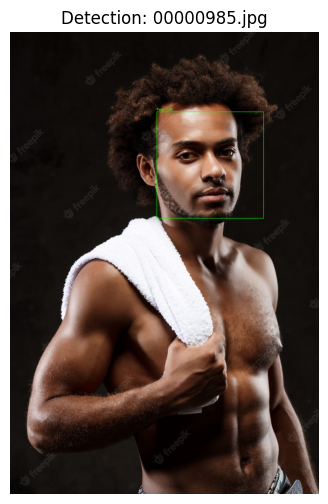

File: 00000661.jpg - Trovati 1 volti.


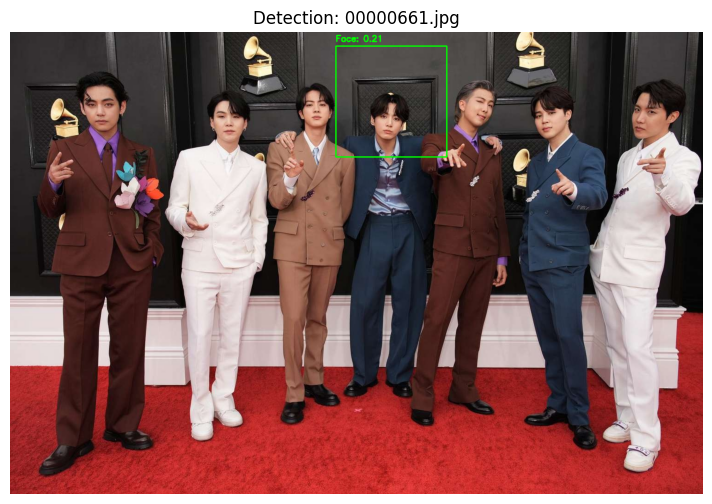

File: 00001650.jpg - Trovati 2 volti.


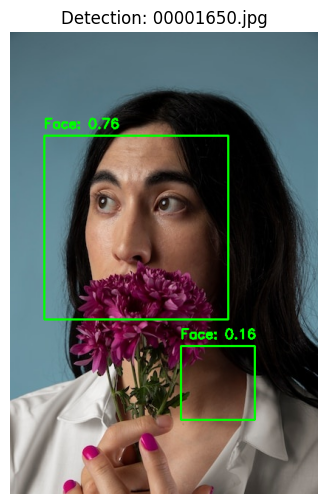

In [ ]:
Num_img = 3
all_images = [f for f in os.listdir(image_dir) if f.endswith(('.jpg', '.png', '.jpeg'))]

sample_images = random.sample(all_images, Num_img)

for filename in sample_images:
    img_path = os.path.join(image_dir, filename)
    image_bgr = cv2.imread(img_path)
    if image_bgr is None:
        print(f"Errore nel caricamento di: {filename}")
        continue

    boxes, probs = find_faces(image_bgr, clf, scaler)

    print(f"File: {filename} - Trovati {len(boxes)} volti.")

    img_display = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

    if len(boxes) > 0:
        for i, (x1, y1, x2, y2) in enumerate(boxes):
            # Disegna il rettangolo
            cv2.rectangle(img_display, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 2)

            # Scrive il punteggio SVM sopra il rettangolo
            label = f"Face: {probs[i]:.2f}"
            cv2.putText(img_display, label, (int(x1), int(y1)-10),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
    else:
        print("Nessun volto rilevato con la soglia attuale.")

    plt.figure(figsize=(10, 6))
    plt.imshow(img_display)
    plt.title(f"Detection: {filename}")
    plt.axis('off')
    plt.show()

# CONCLUSIONI
Il modello ha un comportamento soddisfacente sui dataset di prova, e si mostra abbastanza veloce nell'addestramento. Le metriche sono molto buone ma questo ci lascia comunque con dei volti non riconosciuti o qualche falso positivo nelle prove fatte. Oltre alle questioni evidenziate nel possibile miglioramento del dataset di ingresso, si può pensare di implementare il modello con Hard Negative Mining [1][9] che consiste in:
- Addestrare il modello su un dataset iniziale.
- Far girare il modello su un set di immagini che non contengono facce.
- Identificazione dei 'Hard Negatives': ogni volta che il modello vede un Falso Positivo, quella finestra viene salvata. È un 'Hard Negative' perché ha ingannato il modello.
- Aggiunta di questi errori specifici al dataset di addestramento originale come esempi negativi per riaddestrare il modello.

Un valutazione più approfondita della bontà del modello si può avere applicandolo su un dataset contenente già le informazioni dei bounding box presenti in modo da poter confronttare in maniera quantitativa le metriche della applicazione. Questa operazione può fornire importanti informazioni ma prevede ovviamente di poter nuovamente applicare il modello su un intero dataset di dimensioni adeguate e aumenta notevolmente il tempo impiegato e il costo computazionale del progetto.

La necessità di ottimizzare il modello per utilizzare poche risorse ci porta però a considerare i buoni risultati ottenuti nel lavoro svolto.
